# Hypotheses v Findings (Combined Dataset)

This notebook reads results directly from the pickled experiment object and reproduces all hypothesis tables and analyses.

---

## Methodology recap

- **Cross-validation**: 10-fold stratified CV. Each fold trains on 9 folds (with inner 3-fold grid search for hyperparameters) and validates on 1 held-out fold.
- **Baseline**: `DummyClassifier(strategy='uniform', random_state=42)` — a random uniform classifier.
- **Statistical testing**: For each model, fold validation scores are compared to baseline fold validation scores. A **paired t-test** (`ttest_rel`, one-sided, `alternative='greater'`) is used when the Shapiro–Wilk test on the pairwise differences does not reject normality (p > 0.05). Otherwise a **Wilcoxon signed-rank test** (one-sided, `alternative='greater'`) is used as a non-parametric fallback.
- **Fold wins**: number of folds in which the model's validation accuracy exceeds the baseline's validation accuracy.
- **Best model**: selected by highest mean fold validation accuracy across all non-baseline classifiers.

## Setup

In [1]:
import os
import pickle
import warnings
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

%cd "/home/adam/personal/msc/thesis/Data and code"
from adamthesis.gridsearch import *

PICKLES_DIR = 'logs/pickles'
PICKLE_SUFFIX = '_10folding_with_stats.pkl'
PICKLE_PATH = os.path.join(PICKLES_DIR, 'summary_results' + PICKLE_SUFFIX)
CONFUSION_MATRICES_SAVE_PATH = 'notebooks/confusion_matrices'


SEGMENTS   = ['individual-491', 'individual-492']
SEG_LABELS = ['Individual 491', 'Individual 492']
NON_BASELINE_MODELS = ['random_forest', 'svc', 'logistic_regression',
                        'naive_bayes', 'KNN', 'DecisionTree']

data = {}
for fname in sorted(os.listdir(PICKLES_DIR)):
    if not fname.endswith(PICKLE_SUFFIX) or fname.startswith('summary_'):
        continue
    stem = fname[:-len(PICKLE_SUFFIX)]
    segment, _, feature_key = stem.partition('_')
    with open(os.path.join(PICKLES_DIR, fname), 'rb') as f:
        data.setdefault(segment, {})[feature_key] = pickle.load(f)


print("Loaded segments:", list(data.keys()))

/home/adam/personal/msc/thesis/Data and code
Loaded segments: ['group-491', 'group-492', 'individual-491', 'individual-492']


## Helper functions

In [2]:
import matplotlib.pyplot as plt
from IPython.display import Markdown


def get_fold_scores(exp, model_name):
    """Return per-fold validation scores for a named model from exp.results."""
    for r in exp.results:
        if r['model'] == model_name:
            return np.array(r['fold_val_scores'], dtype=float)
    raise KeyError(f"Model '{model_name}' not found in results")


def get_best_model(exp):
    """Return (model_name, mean_acc, fold_scores) for the best non-baseline model."""
    best_name, best_mean, best_scores = None, -1.0, None
    for r in exp.results:
        if r['model'] == 'baseline_classifier':
            continue
        scores = np.array(r['fold_val_scores'], dtype=float)
        m = scores.mean()
        if m > best_mean:
            best_mean, best_name, best_scores = m, r['model'], scores
    return best_name, best_mean, best_scores


def is_normal(diffs, alpha=0.05):
    """Shapiro-Wilk normality test on a difference vector."""
    _, sw_p = stats.shapiro(diffs)
    return sw_p > alpha, round(sw_p, 4)


def paired_test(scores_a, scores_b):
    """
    One-sided test: H1 = mean(scores_a) > mean(scores_b).
    Uses paired t-test if differences are normal, Wilcoxon otherwise.
    Returns (test_name, statistic, p_value, normal, sw_p)
    """
    diffs = np.array(scores_a) - np.array(scores_b)
    normal, sw_p = is_normal(diffs)
    if normal:
        t, p2 = stats.ttest_rel(scores_a, scores_b)
        p = p2 / 2 if t > 0 else 1 - p2 / 2
        return 'paired t-test', round(float(t), 4), round(float(p), 4), True, sw_p
    else:
        try:
            stat, p = stats.wilcoxon(diffs, alternative='greater',method='exact')
        except Exception:
            stat, p = 0.0, 1.0
        return 'Wilcoxon *', round(float(stat), 4), round(float(p), 4), False, sw_p

def paired_noninferiority_test(candidate_scores, reference_scores, margin=0.05):
    """
    Non-inferiority test.

    H0: mean(candidate - reference) <= -margin
        Candidate is worse than reference by more than the acceptable margin.

    H1: mean(candidate - reference) > -margin
        Candidate is non-inferior to reference.

    In this notebook:
        candidate = prerequisite-only model
        reference = full academic-history model

    A significant p-value supports non-inferiority.
    """

    candidate_scores = np.array(candidate_scores, dtype=float)
    reference_scores = np.array(reference_scores, dtype=float)

    diffs = candidate_scores - reference_scores

    # Shift by margin so the test becomes:
    # H0: mean(diffs + margin) <= 0
    # H1: mean(diffs + margin) > 0
    adjusted_diffs = diffs + margin

    normal, sw_p = is_normal(adjusted_diffs)

    if normal:
        t, p2 = stats.ttest_1samp(adjusted_diffs, 0.0)
        p = p2 / 2 if t > 0 else 1 - p2 / 2
        return 'paired t-test, non-inferiority', round(float(t), 4), round(float(p), 4), True, sw_p
    else:
        try:
            stat, p = stats.wilcoxon(adjusted_diffs, alternative='greater')
        except Exception:
            stat, p = 0.0, 1.0
        return 'Wilcoxon, non-inferiority *', round(float(stat), 4), round(float(p), 4), False, sw_p

def fmt_p(p):
    return f'{p:.4f}' if p >= 0.0001 else '<0.0001'


def sig_marker(p, threshold=0.05):
    return '✓' if p < threshold else ''


# ── Supplementary metric helpers (F1 / Precision / Recall) ───────────────────

def get_best_model_metrics(exp):
    """Return name / accuracy / F1 / precision / recall (mean fold val) for best non-baseline model."""
    best_name, best_mean, _ = get_best_model(exp)
    result = next(r for r in exp.results if r['model'] == best_name)
    def _mean(key):
        vals = result.get(key, [])
        return float(np.mean(vals)) if vals else float('nan')
    return {
        'name':      best_name,
        'accuracy':  best_mean,
        'f1':        _mean('fold_val_f1'),
        'precision': _mean('fold_val_precision'),
        'recall':    _mean('fold_val_recall'),
    }


def fmt_metric(v):
    return f'{v:.4f}' if not (isinstance(v, float) and np.isnan(v)) else 'N/A'


def rq_metric_table(feature_key, rq_label):
    """Per-segment best-model metrics for one feature set, with baseline metrics alongside."""
    rows = []
    for seg, label in zip(SEGMENTS, SEG_LABELS):
        if feature_key not in data.get(seg, {}):
            continue
        exp = data[seg][feature_key]
        baseline_result = next((r for r in exp.results if r['model'] == 'baseline_classifier'), None)
        m = get_best_model_metrics(exp)
        def _bm(key):
            if baseline_result is None:
                return float('nan')
            vals = baseline_result.get(key, [])
            return float(np.mean(vals)) if vals else float('nan')
        rows.append({
            'Experiment':     f'{rq_label} → {label}',
            'Best Model':     m['name'],
            'Acc.':           f"{m['accuracy']:.2%}",
            'F1':             fmt_metric(m['f1']),
            'Precision':      fmt_metric(m['precision']),
            'Recall':         fmt_metric(m['recall']),
            'Baseline F1':    fmt_metric(_bm('fold_val_f1')),
            'Baseline Prec.': fmt_metric(_bm('fold_val_precision')),
            'Baseline Rec.':  fmt_metric(_bm('fold_val_recall')),
        })
    return pd.DataFrame(rows).set_index('Experiment')


# ── Out-of-fold confusion matrix (best non-baseline model only) ──────────────

def display_oof_confusion_matrices(exp, seg_label, feat_label):
    """Plot the OOF confusion matrix of the best non-baseline model from run_with_folding().

    Older pickles also contain a flat 'training' DataFrame in confusion_matrices —
    a leftover from a previous version of generate_confusion_matrices() — which is
    ignored here. If the best model has no nested 'validation' entry, the pickle
    pre-dates the per-model OOF matrix change and a re-run is needed.
    """
    best_name, _, _ = get_best_model(exp)
    cm_entry = exp.confusion_matrices.get(best_name)
    cm_df = cm_entry['validation'] if isinstance(cm_entry, dict) and 'validation' in cm_entry else None
    if cm_df is None:
        print(f"  [{seg_label[-3:]} | {feat_label}] No OOF validation matrix for best model "
              f"'{best_name}'. Pickle is likely from an older run — re-run the experiment "
              f"to populate per-model OOF matrices.")
        return
    fig, ax = plt.subplots(figsize=(2.8, 2.6))
    try:
        cm_int = cm_df.astype(int).values
    except Exception:
        cm_int = cm_df.values
    ax.imshow(cm_int, cmap='Blues')
    vmax = cm_int.max() if cm_int.size else 1
    for (i, j), v in np.ndenumerate(cm_int):
        ax.text(j, i, str(v), ha='center', va='center',
                color='white' if v > vmax / 2 else 'black', fontsize=9)
    ax.set_xticks(range(cm_df.shape[1]))
    ax.set_yticks(range(cm_df.shape[0]))
    labels = ['Non-AA', 'AA'] if cm_df.shape == (2, 2) else list(cm_df.columns)
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_title(f'{seg_label[-3:]}  |  {feat_label}\nBest: {best_name}', fontsize=9, pad=4)
    ax.set_xlabel('Predicted', fontsize=8)
    ax.set_ylabel('Actual', fontsize=8)
    plt.tight_layout()
    plt.show()
    # save confusion matrices
    os.makedirs(CONFUSION_MATRICES_SAVE_PATH, exist_ok=True)
    save_fname = f'{seg_label}_{feat_label}_{best_name}_oof_confusion_matrix.pdf'.replace(' ', '_')
    save_path = os.path.join(CONFUSION_MATRICES_SAVE_PATH, save_fname)
    fig.savefig(save_path, dpi=300)
    print(f"  [{seg_label} | {feat_label}] OOF confusion matrix saved to: {save_path}")


def show_rq_supplements(feature_key, rq_label):
    """One-shot: print the metric table and per-segment best-model OOF confusion matrix."""
    display(Markdown(f"**{rq_label}: best non-baseline model — mean fold validation metrics**"))
    display(rq_metric_table(feature_key, rq_label))
    display(Markdown(f"**{rq_label}: best-model out-of-fold confusion matrix (per segment)**"))
    for seg, label in zip(SEGMENTS, SEG_LABELS):
        if feature_key in data.get(seg, {}):
            display_oof_confusion_matrices(data[seg][feature_key], label, rq_label)


print("Helper functions defined.")

Helper functions defined.


---
## RQ1 — TWQ features can predict graduation project outcomes better than baseline

For each experiment the best non-baseline model (by mean fold validation accuracy) is compared against the baseline using a one-sided paired test on their fold-level accuracy vectors.

In [3]:
rq1_rows = []
for seg, label in zip(SEGMENTS, SEG_LABELS):
    exp = data[seg]['twq']
    baseline_scores = get_fold_scores(exp, 'baseline_classifier')
    best_name, best_mean, best_scores = get_best_model(exp)
    baseline_mean = baseline_scores.mean()
    wins = int((best_scores > baseline_scores).sum())
    test_name, stat, p, normal, sw_p = paired_test(best_scores, baseline_scores)
    rq1_rows.append({
        'Experiment':        f'TWQ → {label}',
        'Best Model':        best_name,
        'Mean Fold Acc.':    f'{best_mean:.0%}',
        'Baseline Acc.':     f'{baseline_mean:.0%}',
        'Δ Accuracy':        f'{best_mean - baseline_mean:+.0%}',
        'Fold Wins / 10':    wins,
        'Normal (SW p)':     f'{"Yes" if normal else "No"} ({sw_p})',
        'Test':              test_name,
        'Statistic':         stat,
        'p-value':           fmt_p(p),
        'Significant?':      sig_marker(p),
        '_summary_cell':     f"{'✓' if p < 0.05 else '✗'} p={fmt_p(p)}{'' if normal else ' (W)'}",
    })

df_rq1 = pd.DataFrame(rq1_rows)
print("* Wilcoxon signed-rank test used where normality was rejected.")
display(df_rq1.drop(columns=['_summary_cell']).set_index('Experiment'))

* Wilcoxon signed-rank test used where normality was rejected.


,Best Model,Mean Fold Acc.,Baseline Acc.,Δ Accuracy,Fold Wins / 10,Normal (SW p),Test,Statistic,p-value,Significant?
Experiment,,,,,,,,,,
TWQ → Individual 491,svc,68%,56%,+12%,6,Yes (0.4726),paired t-test,2.1669,0.0292,✓
TWQ → Individual 492,svc,67%,50%,+17%,9,Yes (0.0949),paired t-test,5.0747,0.0003,✓


In [4]:
sig_count = sum(1 for r in rq1_rows if r['Significant?'] == '✓')
print(f"Significant in {sig_count}/{len(SEGMENTS)} experiments.")
if sig_count == len(SEGMENTS):
    print("→ Hypothesis ACCEPTED (all setups)")
elif sig_count == 0:
    print("→ Hypothesis REJECTED (no setups)")
else:
    print(f"→ Hypothesis PARTIALLY ACCEPTED ({sig_count}/{len(SEGMENTS)} setups)")

Significant in 2/2 experiments.
→ Hypothesis ACCEPTED (all setups)


**TWQ: best non-baseline model — mean fold validation metrics**

,Best Model,Acc.,F1,Precision,Recall,Baseline F1,Baseline Prec.,Baseline Rec.
Experiment,,,,,,,,
TWQ → Individual 491,svc,68.00%,0.6811,0.6155,0.7750,0.4214,0.5333,0.3500
TWQ → Individual 492,svc,67.00%,0.7080,0.6891,0.7567,0.3972,0.5667,0.3067


**TWQ: best-model out-of-fold confusion matrix (per segment)**

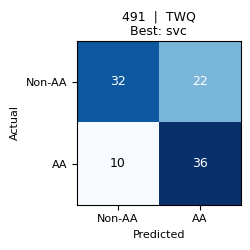

  [Individual 491 | TWQ] OOF confusion matrix saved to: notebooks/confusion_matrices/Individual_491_TWQ_svc_oof_confusion_matrix.pdf


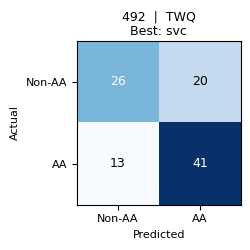

  [Individual 492 | TWQ] OOF confusion matrix saved to: notebooks/confusion_matrices/Individual_492_TWQ_svc_oof_confusion_matrix.pdf


In [5]:
show_rq_supplements('twq', 'TWQ')

---
## RQ2 — Academic history features can predict graduation project outcomes better than baseline

In [6]:
rq2_rows = []
for seg, label in zip(SEGMENTS, SEG_LABELS):
    exp = data[seg]['academic']
    baseline_scores = get_fold_scores(exp, 'baseline_classifier')
    best_name, best_mean, best_scores = get_best_model(exp)
    baseline_mean = baseline_scores.mean()
    wins = int((best_scores > baseline_scores).sum())
    test_name, stat, p, normal, sw_p = paired_test(best_scores, baseline_scores)
    rq2_rows.append({
        'Experiment':        f'Academic → {label}',
        'Best Model':        best_name,
        'Mean Fold Acc.':    f'{best_mean:.0%}',
        'Baseline Acc.':     f'{baseline_mean:.0%}',
        'Δ Accuracy':        f'{best_mean - baseline_mean:+.0%}',
        'Fold Wins / 10':    wins,
        'Normal (SW p)':     f'{"Yes" if normal else "No"} ({sw_p})',
        'Test':              test_name,
        'Statistic':         stat,
        'p-value':           fmt_p(p),
        'Significant?':      sig_marker(p),
        '_summary_cell':     f"{'✓' if p < 0.05 else '✗'} p={fmt_p(p)}{'' if normal else ' (W)'}",
    })

df_rq2 = pd.DataFrame(rq2_rows)
print("* Wilcoxon signed-rank test used where normality was rejected.")
display(df_rq2.drop(columns=['_summary_cell']).set_index('Experiment'))

* Wilcoxon signed-rank test used where normality was rejected.


,Best Model,Mean Fold Acc.,Baseline Acc.,Δ Accuracy,Fold Wins / 10,Normal (SW p),Test,Statistic,p-value,Significant?
Experiment,,,,,,,,,,
Academic → Individual 491,random_forest,74%,56%,+18%,10,No (0.0042),Wilcoxon *,55.0000,0.0010,✓
Academic → Individual 492,logistic_regression,69%,50%,+19%,9,Yes (0.4851),paired t-test,4.1461,0.0012,✓


In [7]:
sig_count = sum(1 for r in rq2_rows if r['Significant?'] == '✓')
print(f"Significant in {sig_count}/{len(SEGMENTS)} experiments.")
if sig_count == len(SEGMENTS):
    print("→ Hypothesis ACCEPTED (all setups)")
elif sig_count == 0:
    print("→ Hypothesis REJECTED (no setups)")
else:
    print(f"→ Hypothesis PARTIALLY ACCEPTED ({sig_count}/{len(SEGMENTS)} setups)")

Significant in 2/2 experiments.
→ Hypothesis ACCEPTED (all setups)


**Academic: best non-baseline model — mean fold validation metrics**

,Best Model,Acc.,F1,Precision,Recall,Baseline F1,Baseline Prec.,Baseline Rec.
Experiment,,,,,,,,
Academic → Individual 491,random_forest,74.00%,0.7158,0.7092,0.7550,0.4214,0.5333,0.3500
Academic → Individual 492,logistic_regression,69.00%,0.6867,0.7869,0.6667,0.3972,0.5667,0.3067


**Academic: best-model out-of-fold confusion matrix (per segment)**

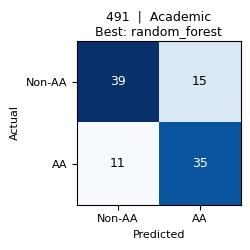

  [Individual 491 | Academic] OOF confusion matrix saved to: notebooks/confusion_matrices/Individual_491_Academic_random_forest_oof_confusion_matrix.pdf


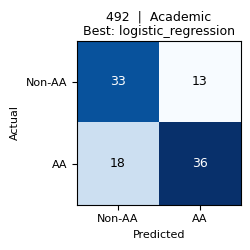

  [Individual 492 | Academic] OOF confusion matrix saved to: notebooks/confusion_matrices/Individual_492_Academic_logistic_regression_oof_confusion_matrix.pdf


In [8]:
show_rq_supplements('academic', 'Academic')


---
## RQ3 — Academic is significantly more predictive than academic history

Direct comparison of the best-model mean fold accuracy for TWQ vs Academic features.

In [9]:
# ---------------------------------------------------------------------
# RQ3 — Academic history is more predictive than TWQ
# ---------------------------------------------------------------------

rq3_rows = []

for seg, label in zip(SEGMENTS, SEG_LABELS):
    twq_name,  twq_mean,  twq_scores  = get_best_model(data[seg]['twq'])
    acad_name, acad_mean, acad_scores = get_best_model(data[seg]['academic'])

    delta = acad_mean - twq_mean
    wins = int((acad_scores > twq_scores).sum())

    # One-sided paired test: Academic > TWQ
    test_name, stat, p, normal, sw_p = paired_test(acad_scores, twq_scores)

    winner = 'Academic' if delta > 0 else ('TWQ' if delta < 0 else 'Tie')

    rq3_rows.append({
        'Experiment':             label,
        'Academic Best Model':    acad_name,
        'Academic Mean Acc.':     f'{acad_mean:.0%}',
        'TWQ Best Model':         twq_name,
        'TWQ Mean Acc.':          f'{twq_mean:.0%}',
        'Δ (Academic − TWQ)':     f'{delta:+.0%}',
        'Academic Fold Wins / 10': wins,
        'Normal (SW p)':          f'{"Yes" if normal else "No"} ({sw_p})',
        'Test (Academic > TWQ)':  test_name,
        'Statistic':              stat,
        'p-value':                fmt_p(p),
        'H3 Supported?':          '✓' if p < 0.05 else '✗',
        'Mean Winner':            winner,
        '_summary_cell':          f"{'✓' if p < 0.05 else '✗'} p={fmt_p(p)}{'' if normal else ' (W)'}",
    })

df_rq3 = pd.DataFrame(rq3_rows)
display(df_rq3.drop(columns=['_summary_cell']).set_index('Experiment'))

supported = sum(1 for r in rq3_rows if r['H3 Supported?'] == '✓')
print(f"\nAcademic significantly outperforms TWQ in {supported}/{len(rq3_rows)} experiments.")

,Academic Best Model,Academic Mean Acc.,TWQ Best Model,TWQ Mean Acc.,Δ (Academic − TWQ),Academic Fold Wins / 10,Normal (SW p),Test (Academic > TWQ),Statistic,p-value,H3 Supported?,Mean Winner
Experiment,,,,,,,,,,,,
Individual 491,random_forest,74%,svc,68%,+6%,5,Yes (0.0944),paired t-test,1.3270,0.1086,✗,Academic
Individual 492,logistic_regression,69%,svc,67%,+2%,4,Yes (0.1583),paired t-test,0.4286,0.3392,✗,Academic



Academic significantly outperforms TWQ in 0/2 experiments.


---
## RQ4 — Combined (Academic + TWQ) outperforms either feature set alone

Three paired comparisons are made per experiment:
1. Combined vs. TWQ-only
2. Combined vs. Academic-only
3. Combined vs. per-fold maximum of (TWQ, Academic) — the strictest benchmark

The fold-level accuracy matrices are also shown.

In [10]:
rq4_verdicts = {}
rq4_details = {}

for seg, label in zip(SEGMENTS, SEG_LABELS):
    twq_name,  twq_mean,  twq_scores  = get_best_model(data[seg]['twq'])
    acad_name, acad_mean, acad_scores = get_best_model(data[seg]['academic'])
    both_name, both_mean, both_scores = get_best_model(data[seg]['both'])
    max_scores = np.maximum(twq_scores, acad_scores)

    # ── Fold matrix ──────────────────────────────────────────────────────────
    print(f"\n{'='*60}")
    print(f"  {label}")
    print(f"{'='*60}")
    matrix_rows = []
    for i in range(10):
        t, a, b = twq_scores[i], acad_scores[i], both_scores[i]
        best_val = max(t, a, b)
        tag = ''
        if b == best_val and b > max(t, a):
            tag = '← Best'
        elif b == best_val:
            tag = '← Tied'
        matrix_rows.append({
            'Fold': f'Fold {i+1}',
            f'TWQ ({twq_name})': f'{t:.2f}',
            f'Academic ({acad_name})': f'{a:.2f}',
            f'Combined ({both_name})': f'{b:.2f} {tag}'.strip(),
        })
    matrix_rows.append({
        'Fold': 'Mean',
        f'TWQ ({twq_name})': f'{twq_mean:.2f}',
        f'Academic ({acad_name})': f'{acad_mean:.2f}',
        f'Combined ({both_name})': f'{both_mean:.2f}',
    })
    df_matrix = pd.DataFrame(matrix_rows).set_index('Fold')
    display(df_matrix)

    # ── Statistical comparisons ───────────────────────────────────────────────
    comparisons = [
        ('Combined vs. TWQ',                   both_scores, twq_scores),
        ('Combined vs. Academic',               both_scores, acad_scores),
        ('Combined vs. max(TWQ, Academic)',      both_scores, max_scores),
    ]
    stat_rows = []
    any_sig = False
    for comp_label, a_s, b_s in comparisons:
        test_name, stat, p, normal, sw_p = paired_test(a_s, b_s)
        sig = sig_marker(p)
        if sig and comp_label != 'Combined vs. max(TWQ, Academic)':
            any_sig = True
        stat_rows.append({
            'Comparison':  comp_label,
            'Normal (SW p)': f'{"Yes" if normal else "No"} ({sw_p})',
            'Test':        test_name,
            'Statistic':   stat,
            'p-value':     fmt_p(p),
            'Sig.':        sig,
        })
    print()
    display(pd.DataFrame(stat_rows).set_index('Comparison'))
    verdict = 'ACCEPTED' if any_sig else 'REJECTED'
    rq4_verdicts[label] = verdict
    rq4_details[label] = {'accepted': any_sig, 'both_mean': both_mean}
    print(f"  Hypothesis {verdict} for {label}")

accepted = sum(1 for v in rq4_verdicts.values() if v == 'ACCEPTED')
print(f"\n\nRQ4 Summary: Accepted in {accepted}/{len(SEGMENTS)} experiments.")


  Individual 491


,TWQ (svc),Academic (random_forest),Combined (KNN)
Fold,,,
Fold 1,0.60,0.80,0.70
Fold 2,0.80,0.60,0.70
Fold 3,0.60,0.80,0.90 ← Best
Fold 4,0.70,0.90,0.90 ← Tied
Fold 5,0.50,0.70,0.70 ← Tied
Fold 6,0.80,0.70,0.70
Fold 7,0.70,0.70,0.80 ← Best
Fold 8,0.70,0.70,0.70 ← Tied
Fold 9,0.60,0.70,0.70 ← Tied


,Normal (SW p),Test,Statistic,p-value,Sig.
Comparison,,,,,
Combined vs. TWQ,Yes (0.3435),paired t-test,2.3717,0.0209,✓
Combined vs. Academic,Yes (0.1716),paired t-test,1.5000,0.0839,
"Combined vs. max(TWQ, Academic)",Yes (0.152),paired t-test,0.3180,0.3789,


  Hypothesis ACCEPTED for Individual 491

  Individual 492


,TWQ (svc),Academic (logistic_regression),Combined (KNN)
Fold,,,
Fold 1,0.60,0.80,0.80 ← Tied
Fold 2,0.60,0.60,0.60 ← Tied
Fold 3,0.60,0.80,0.70
Fold 4,0.50,0.70,0.60
Fold 5,0.80,0.70,0.90 ← Best
Fold 6,0.60,0.50,0.80 ← Best
Fold 7,0.70,0.60,0.80 ← Best
Fold 8,0.80,0.80,0.80 ← Tied
Fold 9,0.70,0.80,0.90 ← Best


,Normal (SW p),Test,Statistic,p-value,Sig.
Comparison,,,,,
Combined vs. TWQ,No (0.0359),Wilcoxon *,36.0000,0.0039,✓
Combined vs. Academic,Yes (0.1932),paired t-test,1.8676,0.0473,✓
"Combined vs. max(TWQ, Academic)",Yes (0.2449),paired t-test,1.3093,0.1114,


  Hypothesis ACCEPTED for Individual 492


RQ4 Summary: Accepted in 2/2 experiments.


**Combined (Academic + TWQ): best non-baseline model — mean fold validation metrics**

,Best Model,Acc.,F1,Precision,Recall,Baseline F1,Baseline Prec.,Baseline Rec.
Experiment,,,,,,,,
Combined (Academic + TWQ) → Individual 491,KNN,78.00%,0.7537,0.7867,0.7600,0.4214,0.5333,0.3500
Combined (Academic + TWQ) → Individual 492,KNN,78.00%,0.7918,0.7881,0.8100,0.3972,0.5667,0.3067


**Combined (Academic + TWQ): best-model out-of-fold confusion matrix (per segment)**

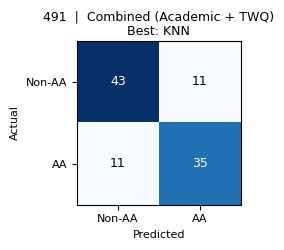

  [Individual 491 | Combined (Academic + TWQ)] OOF confusion matrix saved to: notebooks/confusion_matrices/Individual_491_Combined_(Academic_+_TWQ)_KNN_oof_confusion_matrix.pdf


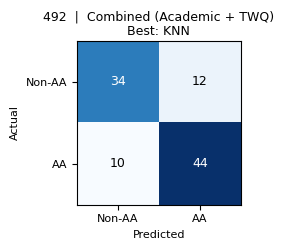

  [Individual 492 | Combined (Academic + TWQ)] OOF confusion matrix saved to: notebooks/confusion_matrices/Individual_492_Combined_(Academic_+_TWQ)_KNN_oof_confusion_matrix.pdf


In [11]:
show_rq_supplements('both', 'Combined (Academic + TWQ)')


---
## RQ5 — Foundational prerequisite courses contain a disproportionately large share of predictive power

The best model trained on **prerequisite courses only** is compared to the best model trained on **all academic features**. If performance is close (i.e. Academic is not significantly better), this implies the prerequisite courses carry most of the predictive signal.

The prerequisite list was originally investigated as a single feature set, but was later split into two complementary lists — **old prereqs** (the historical prerequisite chain, see `data_labels.old_prereqs`) and **new prereqs** (the current curriculum, see `data_labels.new_prereqs`). Both are reported below.

In [12]:
# ---------------------------------------------------------------------
# RQ5 — Prerequisite-only features are non-inferior to full academic history
# ---------------------------------------------------------------------

PREREQ_VARIANTS = [
    ('old-prereqs', 'Old Prereqs'),
    ('new-prereqs', 'New Prereqs'),
]

NI_MARGIN = 0.1  # percentage-point non-inferiority margin

rq5_rows = []

for seg, label in zip(SEGMENTS, SEG_LABELS):
    acad_name, acad_mean, acad_scores = get_best_model(data[seg]['academic'])

    for feat_key, feat_label in PREREQ_VARIANTS:
        if feat_key not in data.get(seg, {}):
            continue

        prereq_name, prereq_mean, prereq_scores = get_best_model(data[seg][feat_key])

        delta = prereq_mean - acad_mean
        wins = int((prereq_scores > acad_scores).sum())

        # Non-inferiority test:
        # H1 = prereq is not worse than academic by more than NI_MARGIN
        test_name, stat, p, normal, sw_p = paired_noninferiority_test(
            prereq_scores,
            acad_scores,
            margin=NI_MARGIN
        )

        supported = 'Yes' if p < 0.05 else 'No'

        rq5_rows.append({
            'Experiment':                  f'{label} — {feat_label}',
            'Academic Best Model':         acad_name,
            'Academic Acc.':               f'{acad_mean:.0%}',
            'Prereqs Best Model':          prereq_name,
            'Prereqs Acc.':                f'{prereq_mean:.0%}',
            'Δ (Prereqs − Academic)':      f'{delta:+.0%}',
            'Prereq Fold Wins / 10':       wins,
            'Non-inferiority Margin':      f'{NI_MARGIN:.0%}',
            'Normal (SW p)':               f'{"Yes" if normal else "No"} ({sw_p})',
            'Test':                        test_name,
            'Statistic':                   stat,
            'p-value':                     fmt_p(p),
            'H5 Supported?':               supported,
            '_feat_key':                   feat_key,
            '_summary_cell':               f"{'✓' if supported == 'Yes' else '✗'} p={fmt_p(p)}{'' if normal else ' (W)'}",
        })

df_rq5 = pd.DataFrame(rq5_rows)

print(
    f"Note: RQ5 is tested as a non-inferiority hypothesis with a "
    f"{NI_MARGIN:.0%} margin."
)
print(
    "A significant result means the prerequisite-only model is not "
    "meaningfully worse than the full academic-history model."
)
print("* Wilcoxon signed-rank test used where normality was rejected.\n")

display(df_rq5.drop(columns=['_feat_key', '_summary_cell']).set_index('Experiment'))

supported_count = sum(1 for r in rq5_rows if r['H5 Supported?'] == 'Yes')
print(f"\nRQ5 supported in {supported_count}/{len(rq5_rows)} experiments.")

Note: RQ5 is tested as a non-inferiority hypothesis with a 10% margin.
A significant result means the prerequisite-only model is not meaningfully worse than the full academic-history model.
* Wilcoxon signed-rank test used where normality was rejected.



,Academic Best Model,Academic Acc.,Prereqs Best Model,Prereqs Acc.,Δ (Prereqs − Academic),Prereq Fold Wins / 10,Non-inferiority Margin,Normal (SW p),Test,Statistic,p-value,H5 Supported?
Experiment,,,,,,,,,,,,
Individual 491 — Old Prereqs,random_forest,74%,DecisionTree,69%,-5%,3,10%,Yes (0.6377),"paired t-test, non-inferiority",1.0476,0.1611,No
Individual 491 — New Prereqs,random_forest,74%,svc,73%,-1%,4,10%,Yes (0.4102),"paired t-test, non-inferiority",2.0769,0.0338,Yes
Individual 492 — Old Prereqs,logistic_regression,69%,svc,67%,-2%,4,10%,Yes (0.7322),"paired t-test, non-inferiority",1.3950,0.0982,No
Individual 492 — New Prereqs,logistic_regression,69%,logistic_regression,71%,+2%,5,10%,No (0.0042),"Wilcoxon, non-inferiority *",50.0000,0.0088,Yes



RQ5 supported in 2/4 experiments.


**Old Prereqs: best non-baseline model — mean fold validation metrics**

,Best Model,Acc.,F1,Precision,Recall,Baseline F1,Baseline Prec.,Baseline Rec.
Experiment,,,,,,,,
Old Prereqs → Individual 491,DecisionTree,69.00%,0.6584,0.6925,0.6850,0.4214,0.5333,0.3500
Old Prereqs → Individual 492,svc,67.00%,0.6346,0.6708,0.6200,0.3972,0.5667,0.3067


**Old Prereqs: best-model out-of-fold confusion matrix (per segment)**

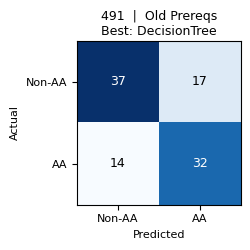

  [Individual 491 | Old Prereqs] OOF confusion matrix saved to: notebooks/confusion_matrices/Individual_491_Old_Prereqs_DecisionTree_oof_confusion_matrix.pdf


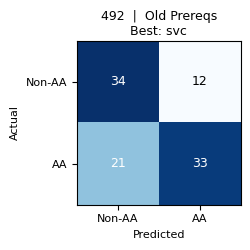

  [Individual 492 | Old Prereqs] OOF confusion matrix saved to: notebooks/confusion_matrices/Individual_492_Old_Prereqs_svc_oof_confusion_matrix.pdf


**New Prereqs: best non-baseline model — mean fold validation metrics**

,Best Model,Acc.,F1,Precision,Recall,Baseline F1,Baseline Prec.,Baseline Rec.
Experiment,,,,,,,,
New Prereqs → Individual 491,svc,73.00%,0.7126,0.7355,0.7150,0.4214,0.5333,0.3500
New Prereqs → Individual 492,logistic_regression,71.00%,0.7137,0.7752,0.6900,0.3972,0.5667,0.3067


**New Prereqs: best-model out-of-fold confusion matrix (per segment)**

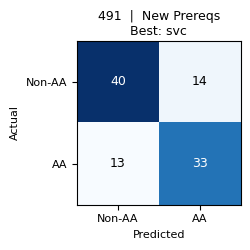

  [Individual 491 | New Prereqs] OOF confusion matrix saved to: notebooks/confusion_matrices/Individual_491_New_Prereqs_svc_oof_confusion_matrix.pdf


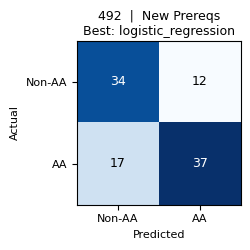

  [Individual 492 | New Prereqs] OOF confusion matrix saved to: notebooks/confusion_matrices/Individual_492_New_Prereqs_logistic_regression_oof_confusion_matrix.pdf


In [13]:
show_rq_supplements('old-prereqs', 'Old Prereqs')
show_rq_supplements('new-prereqs', 'New Prereqs')

---
## Summary Table

In [14]:
#### Pull verdicts directly from each section's stored results
summary_rows = []

# RQ1 — indexed by "TWQ → {label}"
rq1_by_label = {r['Experiment'].split(' → ', 1)[1]: r for r in rq1_rows}
row = {'RQ': 'RQ1', 'Hypothesis': 'TWQ alone beats baseline'}
for label in SEG_LABELS:
    row[label] = rq1_by_label.get(label, {}).get('_summary_cell', '—')
summary_rows.append(row)

# RQ2 — indexed by "Academic → {label}"
rq2_by_label = {r['Experiment'].split(' → ', 1)[1]: r for r in rq2_rows}
row = {'RQ': 'RQ2', 'Hypothesis': 'Academic alone beats baseline'}
for label in SEG_LABELS:
    row[label] = rq2_by_label.get(label, {}).get('_summary_cell', '—')
summary_rows.append(row)

# RQ3 — indexed by label directly
rq3_by_label = {r['Experiment']: r for r in rq3_rows}
row = {'RQ': 'RQ3', 'Hypothesis': 'Academic more predictive than TWQ'}
for label in SEG_LABELS:
    row[label] = rq3_by_label.get(label, {}).get('_summary_cell', '—')
summary_rows.append(row)

# RQ4 — Combined vs best individual (accepted if Combined > TWQ or > Academic sig.)
row = {'RQ': 'RQ4', 'Hypothesis': 'Combined beats either alone'}
for label in SEG_LABELS:
    details = rq4_details.get(label, {})
    accepted = details.get('accepted', False)
    both_mean = details.get('both_mean', float('nan'))
    row[label] = f"{'✓' if accepted else '✗'} {both_mean:.0%}" if not np.isnan(both_mean) else '—'
summary_rows.append(row)

# RQ5a / RQ5b — indexed by "{label} — {feat_label}"
RQ5_VARIANTS_SUMMARY = [
    ('RQ5a', 'Old Prereqs ≈ Full Academic (non-inferior)', 'old-prereqs', 'Old Prereqs'),
    ('RQ5b', 'New Prereqs ≈ Full Academic (non-inferior)', 'new-prereqs', 'New Prereqs'),
]
rq5_by_exp = {r['Experiment']: r for r in rq5_rows}
for rq_id, h_text, feat_key, feat_label in RQ5_VARIANTS_SUMMARY:
    row = {'RQ': rq_id, 'Hypothesis': h_text}
    for label in SEG_LABELS:
        exp_key = f'{label} — {feat_label}'
        row[label] = rq5_by_exp.get(exp_key, {}).get('_summary_cell', '—')
    summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows).set_index(['RQ', 'Hypothesis'])
print("✓ = hypothesis supported / ✗ = not supported | (W) = Wilcoxon used (non-normal differences)")
display(df_summary)

✓ = hypothesis supported / ✗ = not supported | (W) = Wilcoxon used (non-normal differences)


,,Individual 491,Individual 492
RQ,Hypothesis,,
RQ1,TWQ alone beats baseline,✓ p=0.0292,✓ p=0.0003
RQ2,Academic alone beats baseline,✓ p=0.0010 (W),✓ p=0.0012
RQ3,Academic more predictive than TWQ,✗ p=0.1086,✗ p=0.3392
RQ4,Combined beats either alone,✓ 78%,✓ 78%
RQ5a,Old Prereqs ≈ Full Academic (non-inferior),✗ p=0.1611,✗ p=0.0982
RQ5b,New Prereqs ≈ Full Academic (non-inferior),✓ p=0.0338,✓ p=0.0088 (W)
